<h1>BUSI2066 Assignment 1</h1>
<p>10% of the course grade | 100 marks</p>
<h2>Find and fix mistakes in a store report</h2>
<p>A manager used AI to write a report. Check the results and fix the mistakes.</p>
<p>The data in <code>visitors.csv</code> are made up for this assignment.
Each row is one visitor. All spending is in HKD and covers <b>last month</b>.</p>
<table><tr><th>Column</th><th>Meaning</th></tr>
<tr><td>satisfaction</td><td>The visitor's satisfaction answer</td></tr>
<tr><td>time</td><td>Minutes on the website during the last visit</td></tr>
<tr><td>expenditure</td><td>Amount spent last month, in HKD</td></tr>
<tr><td>membership</td><td>1 = member; 0 = nonmember</td></tr></table>
<h3>Instructions</h3>
<ul><li>Put <code>visitors.csv</code> in the same folder as this notebook.
Run the two setup cells. They install the libraries and load the data as <code>v</code>.</li>
<li>Write code and explanations in the answer cells.</li>
<li>AI may help with code. Check its results and write your own conclusions.</li>
<li>Show money to 2 decimal places. Show percentages, r and p values to 4 decimal
places. Round only the final results.</li>
<li>Run all cells and save the notebook with its outputs and charts.
Upload the <code>.ipynb</code> to Moodle by the deadline shown there.
Check that you uploaded the correct file.</li></ul>

In [10]:
%pip install -q pandas numpy seaborn matplotlib scipy


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import bootstrap, pearsonr

v = pd.read_csv('visitors.csv')

<h3>1. Fix the satisfaction percentage (20 marks)</h3><p>The code below gives <b>77.8%</b> satisfied visitors. The correct figure is about <b>56%</b>.</p>
<ol><li>What is wrong? Which answers are left out, and how many? <b>(4 marks)</b></li>
<li>Fix the code without changing the CSV. Count all visitors. Show the count for
 each satisfaction level and the correct percentage. <b>(12 marks)</b></li>
<li>The store's target is at least 60% satisfied visitors. Has it met the target? <b>(4 marks)</b></li></ol>
<p>Count Satisfactory and Very Satisfactory as satisfied.</p>

In [12]:
bad = pd.read_csv('visitors.csv')
order = ['Very Unsatisfactory', 'Unsatisfactory', 'Neutral',
         'Satisfactory', 'Very Satisfactory']
bad['satisfaction'] = pd.Categorical(bad['satisfaction'],
                                     categories=order, ordered=True)
shares = bad['satisfaction'].value_counts(normalize=True, sort=False)
reported_percent = (shares['Satisfactory']
                    + shares['Very Satisfactory']) * 100
print(round(reported_percent, 4))

77.7778


/tmp/ipykernel_12643/3378751816.py:4: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  bad['satisfaction'] = pd.Categorical(bad['satisfaction'],


In [13]:
# Diagnose the omitted response levels before computing the corrected rate.
print('Total visitors:', len(v))
print('\nCounts for every recorded satisfaction response:')
print(v['satisfaction'].value_counts(dropna=False))

satisfied = v['satisfaction'].isin(['Satisfactory', 'Very Satisfactory'])
satisfied_count = int(satisfied.sum())
satisfied_percent = satisfied_count / len(v) * 100

print(f'\nSatisfied visitors: {satisfied_count} / {len(v)} = {satisfied_percent:.4f}%')
print('Target met:', satisfied_percent >= 60)
print('\nResponse-level counts:')
print(v['satisfaction'].value_counts(dropna=False).sort_index())

Total visitors: 150

Counts for every recorded satisfaction response:
satisfaction
Satisfactory           47
Netural                42
Very Satisfactory      37
Very Unsatisfactory    15
Unsatisfactory          9
Name: count, dtype: int64

Satisfied visitors: 84 / 150 = 56.0000%
Target met: False

Response-level counts:
satisfaction
Netural                42
Satisfactory           47
Unsatisfactory          9
Very Satisfactory      37
Very Unsatisfactory    15
Name: count, dtype: int64


**Explanation:** The report's category list used `Neutral`, but the CSV spells this response `Netural`. Converting the column to a categorical with the misspelled level turns all **42 `Netural` answers into missing values**; `value_counts(normalize=True)` then excludes them from its denominator. The corrected calculation includes all **150 visitors**: 47 Satisfactory + 37 Very Satisfactory = 84 satisfied, or **56.0000%**. The store has **not** met its 60% target.

<h3>2. Check the confidence intervals (20 marks)</h3><p>Assume these visitors were picked randomly from the store's visitor population.</p>
<ol><li>Use <code>bootstrap</code> to find a 95% confidence interval for mean monthly
spending. Use <b>10,000 resamples</b> and <code>rng=2026</code>. <b>(4 marks)</b></li>
<li>Repeat at 90% confidence. Keep the other settings the same. Show both intervals. <b>(4 marks)</b></li>
<li>The report says: "The 95% interval contains 95% of visitors' spending.
The 90% interval is more accurate because it is narrower."
What is wrong with these two claims? <b>(12 marks)</b></li></ol>

In [14]:
spending = v['expenditure'].to_numpy()

ci_95 = bootstrap(
    (spending,), np.mean, confidence_level=0.95,
    n_resamples=10_000, rng=2026
).confidence_interval
ci_90 = bootstrap(
    (spending,), np.mean, confidence_level=0.90,
    n_resamples=10_000, rng=2026
).confidence_interval

print(f'Sample mean monthly spending: HK${spending.mean():.2f}')
print(f'95% bootstrap CI: HK${ci_95.low:.2f} to HK${ci_95.high:.2f}')
print(f'90% bootstrap CI: HK${ci_90.low:.2f} to HK${ci_90.high:.2f}')
print(f'95% CI width: HK${ci_95.high - ci_95.low:.2f}')
print(f'90% CI width: HK${ci_90.high - ci_90.low:.2f}')

Sample mean monthly spending: HK$236.96
95% bootstrap CI: HK$213.84 to HK$260.63
90% bootstrap CI: HK$217.41 to HK$256.77
95% CI width: HK$46.79
90% CI width: HK$39.36


**Explanation:** The 95% interval (HK$213.84–HK$260.63) estimates uncertainty about the **population mean monthly spending**, not a range containing 95% of individual visitors' spending. A 95% confidence level describes the long-run success rate of the interval-making procedure: across repeated random samples and bootstrap intervals, about 95% would cover the population mean. The 90% interval (HK$217.41–HK$256.77) is narrower (HK$39.36 versus HK$46.79) because it uses a lower confidence level, not because it is more accurate. It trades coverage confidence for precision.

<h3>3. What if there are more members? (15 marks)</h3><p>Suppose 70% of next month's visitors are members and 30% are nonmembers.
Assume each group's mean spending stays the same.</p>
<ol><li>What percentage of visitors in the current file are members? <b>(3 marks)</b></li>
<li>Estimate next month's mean spending using
<code>0.70 * member_mean + 0.30 * nonmember_mean</code>.
Calculate the current overall mean and compare the two figures. <b>(5 marks)</b></li>
<li>Would more bootstrap runs make the current file match a population with 70% members?
Explain. <b>(4 marks)</b></li>
<li>Give one reason why your estimate could be wrong. <b>(3 marks)</b></li></ol>

In [15]:
member_mask = v['membership'].eq(1)
member_percent = member_mask.mean() * 100
member_mean = v.loc[member_mask, 'expenditure'].mean()
nonmember_mean = v.loc[~member_mask, 'expenditure'].mean()
current_mean = v['expenditure'].mean()
next_month_estimate = 0.70 * member_mean + 0.30 * nonmember_mean

print(f'Current visitors who are members: {member_percent:.4f}%')
print(f'Mean spending, members: HK${member_mean:.2f}')
print(f'Mean spending, nonmembers: HK${nonmember_mean:.2f}')
print(f'Current overall mean: HK${current_mean:.2f}')
print(f'Estimated mean with 70% members: HK${next_month_estimate:.2f}')
print(f'Difference from current mean: HK${next_month_estimate - current_mean:.2f}')

Current visitors who are members: 46.0000%
Mean spending, members: HK$303.91
Mean spending, nonmembers: HK$179.93
Current overall mean: HK$236.96
Estimated mean with 70% members: HK$266.72
Difference from current mean: HK$29.76


**Explanation:** Members currently make up **46.0000%** of visitors. Members spend an average of HK$303.91 and nonmembers HK$179.93, so a 70%/30% mix estimates next month's mean at **HK$266.72**, compared with the current sample mean of **HK$236.96**. More bootstrap resamples only improve the numerical approximation to the current sample's resampling distribution; they do not change its 46% member mix or make it represent a 70% member population. The estimate could be wrong if next month's member or nonmember spending averages differ from this month's (for example, because of promotions or seasonal changes).

<h3>4. Do longer visits go with more spending? (15 marks)</h3><ol><li>Draw a scatter plot of <code>time</code> and <code>expenditure</code>.
Add a title and axis labels with units. <b>(4 marks)</b></li>
<li>Use <code>pearsonr</code>. Report r and the two sided p value. <b>(5 marks)</b></li>
<li>Describe the pattern. At the 5% level, is there evidence of a linear relationship?
Use the p value to explain your answer. <b>(6 marks)</b></li></ol>
<p>Remember: time is for the last visit; spending is for the last month.</p>

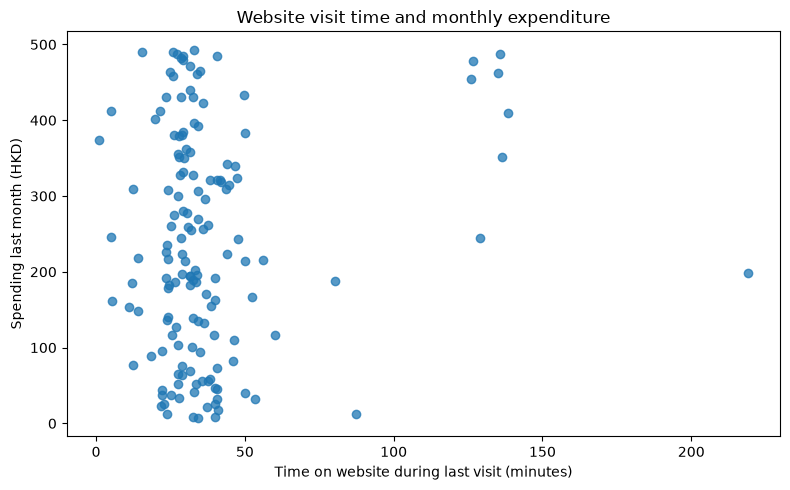

Pearson r: 0.1312
Two-sided p-value: 0.1094


In [16]:
plt.figure(figsize=(8, 5))
plt.scatter(v['time'], v['expenditure'], alpha=0.75)
plt.title('Website visit time and monthly expenditure')
plt.xlabel('Time on website during last visit (minutes)')
plt.ylabel('Spending last month (HKD)')
plt.tight_layout()
plt.show()

r_time_spending, p_time_spending = pearsonr(v['time'], v['expenditure'])
print(f'Pearson r: {r_time_spending:.4f}')
print(f'Two-sided p-value: {p_time_spending:.4f}')

**Explanation:** The scatter plot shows a very weak positive pattern, but the correlation is **r = 0.1312** and the two-sided **p = 0.1094**, which is greater than 0.05. At the 5% level, there is not sufficient evidence of a linear relationship between last-visit website time and last-month spending. The variables also refer to different time periods, so this result should not be read as a causal effect.

<h3>5. Does changing units make the relationship stronger? (15 marks)</h3><p>The report says: "After changing minutes to seconds, the covariance
is much larger. The relationship is therefore stronger."</p>
<ol><li>Create <code>time_seconds = time * 60</code> in a new column. <b>(2 marks)</b></li>
<li>Find the covariance with expenditure before and after the change.
Find r in both cases too. <b>(6 marks)</b></li>
<li>What changed, and by how much? Is the report's claim correct? Explain. <b>(7 marks)</b></li></ol>

In [17]:
v['time_seconds'] = v['time'] * 60

cov_minutes = v['time'].cov(v['expenditure'])
cov_seconds = v['time_seconds'].cov(v['expenditure'])
r_minutes = pearsonr(v['time'], v['expenditure']).statistic
r_seconds = pearsonr(v['time_seconds'], v['expenditure']).statistic

print(f'Covariance (minutes, HKD): {cov_minutes:.4f}')
print(f'Covariance (seconds, HKD): {cov_seconds:.4f}')
print(f'Covariance ratio (seconds / minutes): {cov_seconds / cov_minutes:.4f}')
print(f'Pearson r using minutes: {r_minutes:.4f}')
print(f'Pearson r using seconds: {r_seconds:.4f}')

Covariance (minutes, HKD): 549.2537
Covariance (seconds, HKD): 32955.2200
Covariance ratio (seconds / minutes): 60.0000
Pearson r using minutes: 0.1312
Pearson r using seconds: 0.1312


**Explanation:** Changing minutes to seconds multiplies time by 60, so the covariance also increases by exactly 60: **549.2537** to **32,955.2200** HKD·minutes/seconds. Pearson's r stays **0.1312** in both units because correlation is unitless and invariant to positive rescaling. The report's claim is incorrect: the covariance's numerical size changed, but the strength of the linear relationship did not.

<h3>6. Does taking a log help? (15 marks)</h3><p>The report says: "Taking a log will make the correlation stronger."</p>
<ol><li>Check the smallest time value. Do you need to add 1 before taking its log? Why? <b>(3 marks)</b></li>
<li>Create <code>np.log(time)</code> in a new column. Plot it against expenditure.
Add a title and axis labels. <b>(4 marks)</b></li>
<li>Use <code>pearsonr</code>. Report r and the two sided p value. Compare them with Question 4. <b>(5 marks)</b></li>
<li>Is the report's claim correct here? Why should we avoid trying transformations
only to get a small p value? <b>(3 marks)</b></li></ol>

Minimum time: 1.0000 minutes
Need to add 1 before taking the log: False


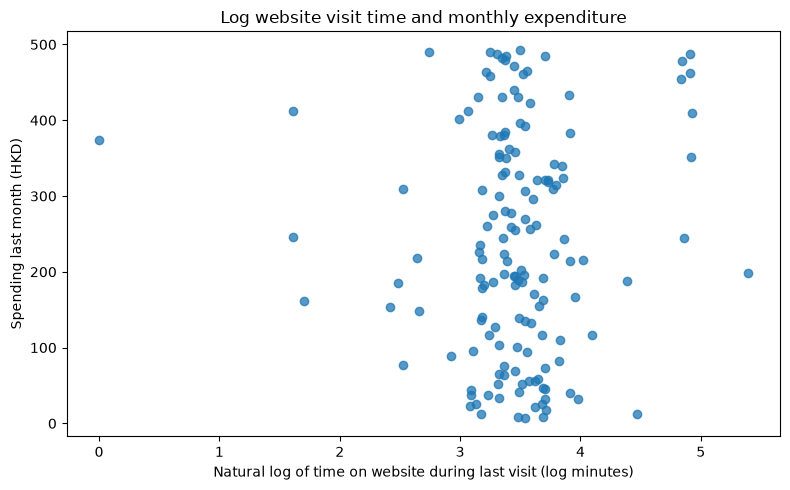

Pearson r with log(time): 0.0385
Two-sided p-value with log(time): 0.6402
Original Pearson r: 0.1312
Original two-sided p-value: 0.1094


In [18]:
minimum_time = v['time'].min()
print(f'Minimum time: {minimum_time:.4f} minutes')
print('Need to add 1 before taking the log:', minimum_time <= 0)

v['log_time'] = np.log(v['time'])

plt.figure(figsize=(8, 5))
plt.scatter(v['log_time'], v['expenditure'], alpha=0.75)
plt.title('Log website visit time and monthly expenditure')
plt.xlabel('Natural log of time on website during last visit (log minutes)')
plt.ylabel('Spending last month (HKD)')
plt.tight_layout()
plt.show()

r_log_time_spending, p_log_time_spending = pearsonr(v['log_time'], v['expenditure'])
print(f'Pearson r with log(time): {r_log_time_spending:.4f}')
print(f'Two-sided p-value with log(time): {p_log_time_spending:.4f}')
print(f'Original Pearson r: {r_time_spending:.4f}')
print(f'Original two-sided p-value: {p_time_spending:.4f}')

**Explanation:** The smallest time is **1.0000 minute**, which is positive, so no `+1` is needed before taking the natural log. After transforming, **r = 0.0385** and **p = 0.6402**, compared with the original **r = 0.1312** and **p = 0.1094**; the log transformation does not strengthen the relationship here. Trying many transformations and reporting only the one with a small p-value is selective analysis (p-hacking): it inflates the chance of a false positive and makes the reported result unreliable. Choose transformations for a clear, defensible reason and report the analyses transparently.